# 03_train_resnet50.ipynb

Fine-tune ResNet-50 trên DurianLDD. Checkpoint chọn bằng macro F1 của validation. Notebook chạy trên Kaggle với GPU.

Cell môi trường kéo nhánh `baseline-ResNet-50` và gắn ảnh từ `cthng123/durian-leaf-disease-dataset`. Split lấy từ `manifests/split_manifest.csv`. Tập test không mở.


## 1. Môi trường

Internet để On. Accelerator chọn GPU. Dataset input là `cthng123/durian-leaf-disease-dataset`.


In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Đổi nhánh tại đây, rồi chạy lại cell.
GIT_BRANCH = "baseline-ResNet-50"
REPO_URL = "https://github.com/meo225/durian-leaf-disease-robustness.git"
REPO_DIR = Path("/kaggle/working") / "durian-leaf-disease-robustness"

if not (Path("/kaggle/working").is_dir() and Path("/kaggle/input").is_dir()):
    raise RuntimeError("Notebook này chỉ chạy trên Kaggle. Xem README, mục Chạy trên Kaggle.")

def git(args, cwd=None):
    subprocess.run(
        ["git", *args],
        cwd=cwd,
        check=True,
        env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
    )


if not (REPO_DIR / ".git").is_dir():
    git(["clone", "--branch", GIT_BRANCH, "--single-branch", REPO_URL, str(REPO_DIR)])
else:
    git(["fetch", "origin", GIT_BRANCH], cwd=REPO_DIR)
    git(["checkout", GIT_BRANCH], cwd=REPO_DIR)
    git(["reset", "--hard", f"origin/{GIT_BRANCH}"], cwd=REPO_DIR)

matches = []
seen = set()
for path in Path("/kaggle/input").rglob("DLD_FinalDataset_224_spit"):
    resolved = str(path.resolve())
    if path.is_dir() and resolved not in seen:
        seen.add(resolved)
        matches.append(path)

if not matches:
    found = []
    input_root = Path("/kaggle/input")
    if input_root.is_dir():
        for path in sorted(input_root.rglob("*")):
            if path.is_dir() and len(path.relative_to(input_root).parts) <= 3:
                found.append(str(path.relative_to(input_root)))
    listing = "\n".join(found[:40]) if found else "(trống)"
    raise FileNotFoundError(
        "Chưa thấy DLD_FinalDataset_224_spit trong /kaggle/input.\n"
        "Add Input: cthng123/durian-leaf-disease-dataset, rồi Save & Run All.\n"
        f"Thư mục hiện có:\n{listing}"
    )

image_root = matches[0].parent
link = REPO_DIR / "datasets" / "durian-ldd"
link.parent.mkdir(parents=True, exist_ok=True)
if link.is_symlink() or link.is_file():
    link.unlink()
elif link.exists():
    link.rmdir()
link.symlink_to(image_root, target_is_directory=True)

if not (link / "DLD_FinalDataset_224_spit").is_dir():
    raise FileNotFoundError(f"Không thấy ảnh tại {link}")

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

commit = subprocess.check_output(
    ["git", "rev-parse", "--short", "HEAD"], cwd=REPO_DIR, text=True
).strip()
branch = subprocess.check_output(
    ["git", "branch", "--show-current"], cwd=REPO_DIR, text=True
).strip()
print(f"Nhánh: {branch}")
print(f"Commit: {commit}")
print(f"Ảnh: {link / 'DLD_FinalDataset_224_spit'}")


Cloning into '/kaggle/working/durian-leaf-disease-robustness'...


Nhánh: baseline-ResNet-50
Commit: 9655bc9
Ảnh: /kaggle/working/durian-leaf-disease-robustness/datasets/durian-ldd/DLD_FinalDataset_224_spit


## 2. Dữ liệu và cấu hình

Ảnh đọc từ dataset Kaggle. Tập train và validation đọc từ cột `split` của manifest.


In [2]:
from src.training.train_resnet50 import load_configs, prepare_loaders

train_cfg, pipeline_cfg = load_configs()
device, loaders = prepare_loaders(pipeline_cfg)

print(f"Thiết bị: {device}")
print(f"Seed: {pipeline_cfg['seed']}")
print(f"Ảnh train: {len(loaders['train'].dataset)}")
print(f"Ảnh validation: {len(loaders['val'].dataset)}")
print(f"Batch size: {pipeline_cfg['batch_size']}")
print(f"Optimizer: {train_cfg['optimizer']}")
print(f"Learning rate: {train_cfg['learning_rate']}")
print(f"Epoch tối đa: {train_cfg['epochs']}")
print(f"Patience: {train_cfg['patience']}")
print("Tập test: không mở")


Thiết bị: cuda
Seed: 42
Ảnh train: 3105
Ảnh validation: 444
Batch size: 32
Optimizer: adamw
Learning rate: 0.0001
Epoch tối đa: 20
Patience: 5
Tập test: không mở


## 3. Model

ResNet-50, trọng số ImageNet, fine-tune toàn bộ mạng, 5 lớp.


In [3]:
from src.models.build import build_model
from src.training.loop import trainable_parameter_count

model = build_model(
    timm_name=train_cfg["timm_name"],
    num_classes=int(pipeline_cfg["num_classes"]),
    pretrained=bool(train_cfg["pretrained"]),
)
print(f"timm: {train_cfg['timm_name']}")
print(f"Số tham số: {trainable_parameter_count(model)}")


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

timm: resnet50
Số tham số: 23518277


## 4. Train

Mỗi epoch in loss, macro F1 và balanced accuracy trên validation. Dòng có chữ `checkpoint` là epoch đang được giữ.


In [4]:
import time

from src.training.loop import fit_model

started = time.perf_counter()
result = fit_model(
    model=model,
    train_loader=loaders["train"],
    val_loader=loaders["val"],
    class_names=list(pipeline_cfg["classes"]),
    train_cfg=train_cfg,
    device=device,
)
elapsed = time.perf_counter() - started
result["trainable_parameters"] = trainable_parameter_count(model)
print(f"Epoch được chọn: {result['best_epoch']}")
print(f"Thời gian train (giây): {elapsed:.1f}")


Epoch 01/20  train_loss=1.5783  val_loss=1.5529  val_macro_f1=0.2144  val_balanced_accuracy=0.2933  checkpoint
Epoch 02/20  train_loss=1.4264  val_loss=1.2626  val_macro_f1=0.5095  val_balanced_accuracy=0.5327  checkpoint
Epoch 03/20  train_loss=0.9843  val_loss=0.7666  val_macro_f1=0.7539  val_balanced_accuracy=0.7527  checkpoint
Epoch 04/20  train_loss=0.5584  val_loss=0.4680  val_macro_f1=0.8479  val_balanced_accuracy=0.8468  checkpoint
Epoch 05/20  train_loss=0.3695  val_loss=0.3434  val_macro_f1=0.8939  val_balanced_accuracy=0.8936  checkpoint
Epoch 06/20  train_loss=0.3036  val_loss=0.2659  val_macro_f1=0.9117  val_balanced_accuracy=0.9109  checkpoint
Epoch 07/20  train_loss=0.2292  val_loss=0.2087  val_macro_f1=0.9239  val_balanced_accuracy=0.9243  checkpoint
Epoch 08/20  train_loss=0.1915  val_loss=0.2127  val_macro_f1=0.9467  val_balanced_accuracy=0.9465  checkpoint
Epoch 09/20  train_loss=0.1780  val_loss=0.2047  val_macro_f1=0.9377  val_balanced_accuracy=0.9377
Epoch 10/20  

## 5. Kết quả validation

Macro F1 là metric chọn checkpoint. Balanced accuracy, recall từng lớp và confusion matrix đi cùng checkpoint đó.


Thiết bị: Tesla T4
Thời gian train (giây): 1162.8
Số tham số: 23518277
Epoch được chọn: 19
Val macro F1: 0.9679
Val balanced accuracy: 0.9676
Val loss: 0.1377
Recall từng lớp:
  ALGAL_LEAF_SPOT: 0.9459
  ALLOCARIDARA_ATTACK: 0.9891
  HEALTHY_LEAF: 0.9794
  LEAF_BLIGHT: 0.9462
  PHOMOPSIS_LEAF_SPOT: 0.9773
Checkpoint: /kaggle/working/durian-leaf-disease-robustness/outputs/checkpoints/resnet50_seed42.pt
Metric: /kaggle/working/durian-leaf-disease-robustness/outputs/results/resnet50_seed42.json
Confusion matrix: /kaggle/working/durian-leaf-disease-robustness/outputs/results/resnet50_seed42_confusion_matrix.png
History: /kaggle/working/durian-leaf-disease-robustness/outputs/results/resnet50_seed42_history.png


,best_epoch,val_macro_f1,val_balanced_accuracy,val_loss,parameters,seconds
0,19,0.967938,0.967593,0.137744,23518277,1162.8


,class_name,recall
0,ALGAL_LEAF_SPOT,0.945946
1,ALLOCARIDARA_ATTACK,0.989130
2,HEALTHY_LEAF,0.979381
3,LEAF_BLIGHT,0.946237
4,PHOMOPSIS_LEAF_SPOT,0.977273


,epoch,train_loss,val_loss,val_macro_f1,val_balanced_accuracy
0,1,1.578276,1.552888,0.214422,0.293320
1,2,1.426426,1.262625,0.509494,0.532699
2,3,0.984267,0.766562,0.753866,0.752732
3,4,0.558420,0.468003,0.847950,0.846775
4,5,0.369503,0.343402,0.893863,0.893604
5,6,0.303589,0.265942,0.911672,0.910880
6,7,0.229168,0.208729,0.923868,0.924282
7,8,0.191537,0.212732,0.946679,0.946460
8,9,0.177953,0.204737,0.937655,0.937677
9,10,0.157543,0.194120,0.942936,0.942242


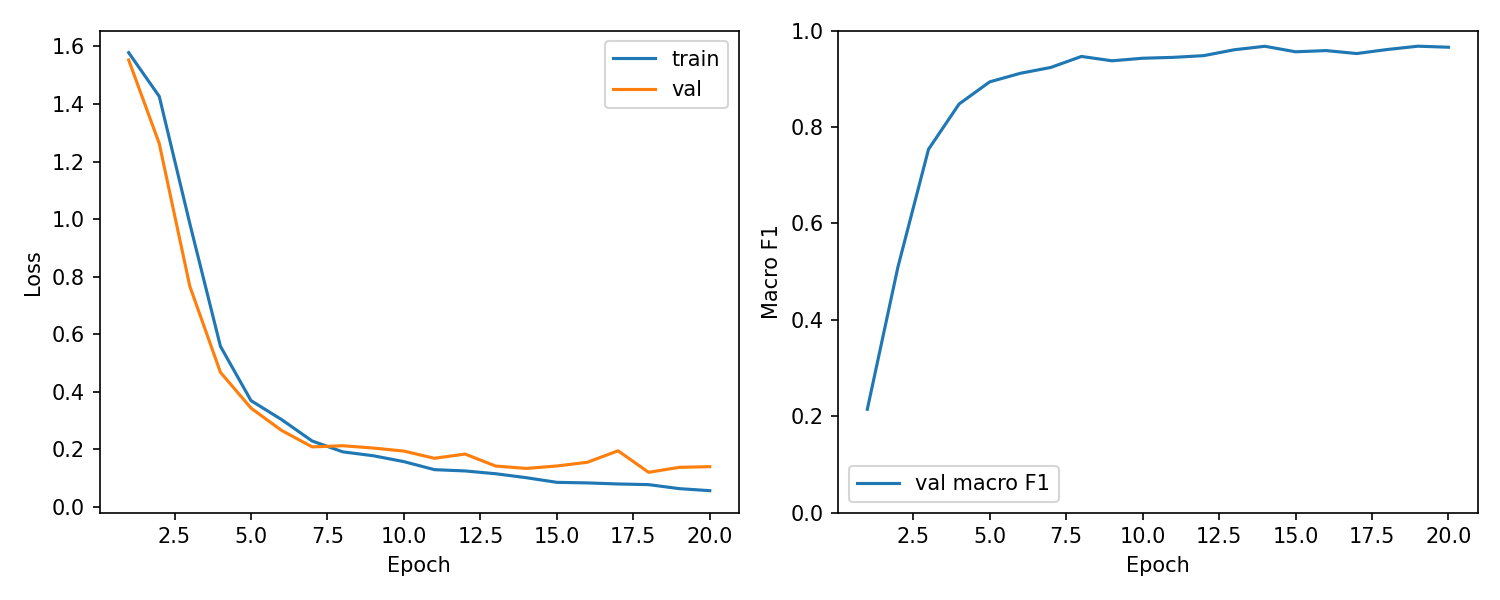

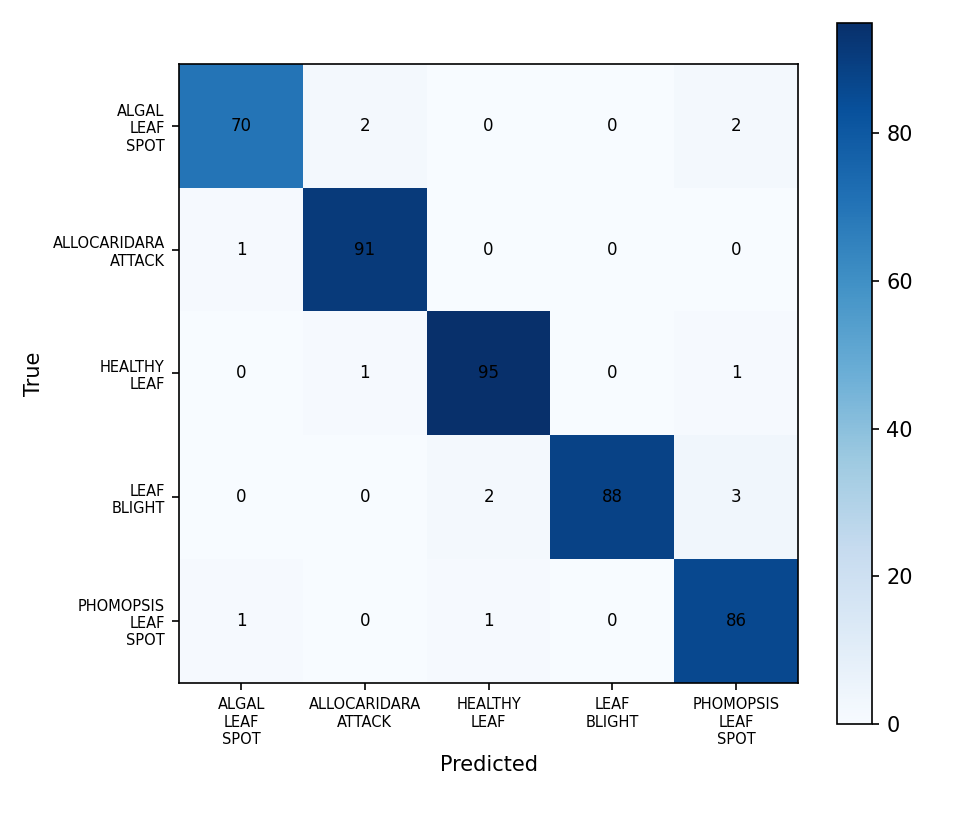

In [5]:
import pandas as pd
from IPython.display import Image, display

from src.training.train_resnet50 import ROOT, print_run_report, save_run_artifacts

paths = save_run_artifacts(
    result=result,
    pipeline_cfg=pipeline_cfg,
    train_cfg=train_cfg,
    device=device,
    elapsed_seconds=elapsed,
    output_dir=ROOT / "outputs",
)
print_run_report(result, paths, device, elapsed)

best = result["best_val"]
display(pd.DataFrame([
    {
        "best_epoch": result["best_epoch"],
        "val_macro_f1": best["macro_f1"],
        "val_balanced_accuracy": best["balanced_accuracy"],
        "val_loss": best["loss"],
        "parameters": result["trainable_parameters"],
        "seconds": round(elapsed, 1),
    }
]))
display(pd.DataFrame(
    [{"class_name": name, "recall": value} for name, value in best["per_class_recall"].items()]
))
display(pd.DataFrame(result["history"]))
display(Image(filename=paths["history"]))
display(Image(filename=paths["confusion_matrix"]))
